# MNIST: model z błędem testowym poniżej 1,62%
**Zadanie z ostatniej komórki:** przeanalizować model z checkpointu `cp.ckpt.weights5.h5` i zbudować model, który zejdzie poniżej **1,62**.

**Jak rozumiem próg.** Checkpoint ma już *loss* 0,42 na teście, więc jako strata próg 1,62 jest spełniony od razu.
Przyjmuję więc, że chodzi o **błąd klasyfikacji w procentach** (accuracy > 98,38%) na pełnym teście MNIST (10 000 obrazów).
W tabelach podaję obie miary.

**Metoda.** Protokół spisany przed treningiem (`PROTOKOL_mnist_1_62.md`, SHA-256 `817321fd…`):
- podział danych: trening 55 000, walidacja 5 000, test 10 000;
- model wybierany wyłącznie na walidacji;
- 3 seedy na każdą próbę;
- test McNemara z korektą Holma.

**Zawartość:** stare podejścia (O1–O3) → trzy nowe próby (P1–P3) → wybór i testy → rekomendacja → **tabela zbiorcza na końcu**.

In [1]:
import os, json, time
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
import numpy as np, pandas as pd, tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers
from scipy.stats import binomtest

CKPT = 'cp.ckpt.weights5.h5'      # plik z checkpointem (ścieżka do zmiany w Colab)
RUN_P3 = False   # CNN: na CPU ~2 h; w Colab z GPU ustaw True (kilka minut)
RES = 'results'                    # tu trafiają/są wyniki; jeśli istnieją, notebook ich nie trenuje ponownie
os.makedirs(RES, exist_ok=True)
print('TensorFlow', tf.__version__)

I0000 00:00:1795601785.022393    3381 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1795601786.327159    3381 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow 2.21.0


## 1. Dane

In [2]:
try:
    (x, y), (xt, yt) = keras.datasets.mnist.load_data()
except Exception as e:                       # brak dostępu do storage.googleapis.com → lokalna kopia
    print('keras.datasets niedostępne, używam mnist.npz:', type(e).__name__)
    d = np.load('mnist.npz'); x, y, xt, yt = d['x_train'], d['y_train'], d['x_test'], d['y_test']
x, xt = x.astype('float32') / 255.0, xt.astype('float32') / 255.0
y, yt = y.astype('int64'), yt.astype('int64')
Xtr, ytr, Xva, yva = x[:55000], y[:55000], x[55000:], y[55000:]   # walidacja = ostatnie 5000
Xte, yte = xt, yt
X1k, y1k = x[:1000].reshape(-1, 784), y[:1000]                      # dane z tutorialu
print(Xtr.shape, Xva.shape, Xte.shape)

keras.datasets niedostępne, używam mnist.npz: Exception


(55000, 28, 28) (5000, 28, 28) (10000, 28, 28)


In [3]:
LOSS = keras.losses.SparseCategoricalCrossentropy(from_logits=True)
def compile_(m, lr=1e-3):
    m.compile(optimizer=keras.optimizers.Adam(lr), loss=LOSS,
              metrics=[keras.metrics.SparseCategoricalAccuracy(name='acc')])
    return m

def logits(m, X):
    return np.concatenate([m(tf.constant(X[i:i+2000]), training=False).numpy() for i in range(0, len(X), 2000)])

def scores(lg, y):
    return float(LOSS(y, lg).numpy()), float(100 * (lg.argmax(1) != y).mean())   # (loss, błąd %)

## 2. Analiza checkpointu i stare podejścia
Plik zawiera wagi sieci `Dense(512, relu) → Dropout(0.2) → Dense(10)` (407 050 parametrów) oraz stan optymalizatora Adam.
Licznik kroków wynosi **320**, czyli 10 epok × 32 batche po 32 próbki. Model widział więc tylko **1000 obrazów** treningowych (tutorial TF *Save and load models*).
- **O1**: ta sama sieć bez treningu (punkt odniesienia: losowe zgadywanie).
- **O2**: wagi wczytane z checkpointu.
- **O3**: ta sama sieć trenowana 50 epok na 1000 próbkach (wariant tutorialu z zapisem co 5 epok).

In [4]:
def tutorial_model():
    return compile_(keras.Sequential([layers.Input((784,)), layers.Dense(512, activation='relu'),
                                      layers.Dropout(0.2), layers.Dense(10)]))
Xte_f = Xte.reshape(-1, 784)
old = {}
keras.utils.set_random_seed(0)
m = tutorial_model(); old['O1'] = scores(logits(m, Xte_f), yte) + (m.count_params(),)

import shutil; shutil.copy(CKPT, 'cp.weights.h5')       # Keras 3 wymaga końcówki .weights.h5
m = tutorial_model(); m.load_weights('cp.weights.h5')
old['O2'] = scores(logits(m, Xte_f), yte) + (m.count_params(),)
import h5py
with h5py.File(CKPT, 'r') as f:
    print('Warstwy w pliku:', list(f['layers']), '| kroki Adama:', int(f['optimizer/vars/0'][()]),
          '| lr:', float(f['optimizer/vars/1'][()]))
print('O2 na test[:1000] (jak w tutorialu):', scores(logits(m, Xte_f[:1000]), yte[:1000]))

keras.utils.set_random_seed(0)
m = tutorial_model(); m.fit(X1k, y1k, epochs=50, batch_size=32, verbose=0)
old['O3'] = scores(logits(m, Xte_f), yte) + (m.count_params(),)
for k, (l, e, p) in old.items(): print(f'{k}: loss={l:.3f}  błąd={e:.2f}%')

/usr/local/lib/python3.13/site-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam_1', because it has 2 variables whereas the saved optimizer has 10 variables. 
  saveable.load_own_variables(store)


Warstwy w pliku: ['dense', 'dense_1', 'dropout'] | kroki Adama: 320 | lr: 0.0010000000474974513
O2 na test[:1000] (jak w tutorialu): (0.41568517684936523, 13.700000000000001)


O1: loss=2.392  błąd=92.79%
O2: loss=0.375  błąd=11.48%
O3: loss=0.446  błąd=10.56%


**Wniosek z analizy:** ograniczeniem checkpointu nie jest architektura, tylko **dane**. 1000 obrazów to 1,7% zbioru treningowego.
Błąd ~11,5% wynika z niedouczenia na małej próbce. Dłuższy trening na tych samych 1000 obrazach (O3) nic nie daje, bo sieć ma już 100% trafności na treningu.

## 3. Trzy nowe próby (pełne dane, 3 seedy każda)
Wspólne ustawienia:
- Adam, batch 128;
- EarlyStopping na `val_loss` (patience 4, przywrócenie najlepszych wag);
- P2 i P3 mają dodatkowo ReduceLROnPlateau.

Augmentacje (przesunięcia, obroty, zoom) są warstwami modelu i działają tylko podczas treningu.

In [5]:
def aug(shift_only=False):
    seq = [layers.Reshape((28, 28, 1)), layers.RandomTranslation(0.1, 0.1, fill_mode='constant')]
    if not shift_only:
        seq += [layers.RandomRotation(8/360, fill_mode='constant'), layers.RandomZoom(0.1, fill_mode='constant')]
    return seq

def p1_model():   # PRÓBA 1: ta sama sieć co w checkpoincie, ale pełne dane + early stopping
    return keras.Sequential([layers.Input((28, 28)), layers.Reshape((784,)),
                             layers.Dense(512, activation='relu'), layers.Dropout(0.2), layers.Dense(10)])

def p2_model():   # PRÓBA 2: szersze MLP 2×1024 + BatchNorm + Dropout 0.3 + przesunięcia
    L = [layers.Input((28, 28))] + aug(shift_only=True) + [layers.Flatten()]
    for _ in range(2):
        L += [layers.Dense(1024, use_bias=False), layers.BatchNormalization(), layers.ReLU(), layers.Dropout(0.3)]
    return keras.Sequential(L + [layers.Dense(10)])

def p3_model():   # PRÓBA 3: CNN (2 bloki konwolucyjne) + BatchNorm + Dropout + augmentacje
    def block(f):
        return [layers.Conv2D(f, 3, padding='same', use_bias=False), layers.BatchNormalization(), layers.ReLU(),
                layers.Conv2D(f, 3, padding='same', use_bias=False), layers.BatchNormalization(), layers.ReLU(),
                layers.MaxPooling2D(), layers.Dropout(0.25)]
    L = [layers.Input((28, 28))] + aug() + block(32) + block(64) + [
        layers.Flatten(), layers.Dense(128, use_bias=False), layers.BatchNormalization(), layers.ReLU(),
        layers.Dropout(0.4), layers.Dense(10)]
    return keras.Sequential(L)

SPECS = {'P1': (p1_model, 30, False), 'P2': (p2_model, 30, True), 'P3': (p3_model, 20, True)}
NAMES = {'P1': 'P1 · ta sama sieć, pełne dane', 'P2': 'P2 · MLP 2×1024 + BN + aug.', 'P3': 'P3 · CNN + BN + aug.'}

def run(name, seed):
    f = f'{RES}/{name}_s{seed}.json'
    if os.path.exists(f):                                   # wynik już policzony → wczytaj
        return json.load(open(f))
    build, ep, plateau = SPECS[name]
    keras.utils.set_random_seed(seed)
    m = compile_(build())
    cb = [keras.callbacks.EarlyStopping('val_loss', patience=4, restore_best_weights=True)]
    if plateau: cb.append(keras.callbacks.ReduceLROnPlateau('val_loss', factor=0.5, patience=2, min_lr=1e-5))
    t = time.time(); h = m.fit(Xtr, ytr, validation_data=(Xva, yva), epochs=ep, batch_size=128, callbacks=cb, verbose=0)
    lv, lt = logits(m, Xva), logits(m, Xte)
    np.save(f'{RES}/{name}_s{seed}_val.npy', lv); np.save(f'{RES}/{name}_s{seed}_test.npy', lt)
    (vl, ve), (tl, te) = scores(lv, yva), scores(lt, yte)
    r = dict(method=name, seed=seed, params=int(m.count_params()), epochs=len(h.history['loss']),
             train_s=round(time.time() - t, 1), val_loss=vl, val_err=ve, test_loss=tl, test_err=te,
             history={k: [float(v) for v in vs] for k, vs in h.history.items()})
    json.dump(r, open(f, 'w'))
    return r

### Próba 1: ta sama architektura, pełne dane
Ta sama sieć co w checkpoincie: czy wystarczą same dane?

In [6]:
R_P1 = [run('P1', s) for s in (0, 1, 2)]

for r in R_P1:
    print(f"seed {r['seed']}: epok={r['epochs']:2d}  val błąd={r['val_err']:.2f}%  test błąd={r['test_err']:.2f}%  test loss={r['test_loss']:.4f}  ({r['train_s']:.0f} s)")
if R_P1: print(f"średni błąd testowy: {np.mean([r['test_err'] for r in R_P1]):.2f}%   parametry: {R_P1[0]['params']:,}")

seed 0: epok=10  val błąd=1.78%  test błąd=1.97%  test loss=0.0651  (26 s)
seed 1: epok=13  val błąd=1.50%  test błąd=1.80%  test loss=0.0614  (38 s)
seed 2: epok=13  val błąd=1.70%  test błąd=1.74%  test loss=0.0588  (34 s)
średni błąd testowy: 1.84%   parametry: 407,050


### Próba 2: szersze MLP + BatchNorm + augmentacja przesunięć
Nadal sieć w pełni połączona, ale z normalizacją i regularyzacją.

In [7]:
R_P2 = [run('P2', s) for s in (0, 1, 2)]

for r in R_P2:
    print(f"seed {r['seed']}: epok={r['epochs']:2d}  val błąd={r['val_err']:.2f}%  test błąd={r['test_err']:.2f}%  test loss={r['test_loss']:.4f}  ({r['train_s']:.0f} s)")
if R_P2: print(f"średni błąd testowy: {np.mean([r['test_err'] for r in R_P2]):.2f}%   parametry: {R_P2[0]['params']:,}")

seed 0: epok=30  val błąd=0.90%  test błąd=0.94%  test loss=0.0272  (280 s)
seed 1: epok=30  val błąd=0.70%  test błąd=0.86%  test loss=0.0247  (271 s)
seed 2: epok=27  val błąd=0.84%  test błąd=1.08%  test loss=0.0333  (263 s)
średni błąd testowy: 0.96%   parametry: 1,869,834


### Próba 3: sieć konwolucyjna (CNN) + augmentacje
CNN korzysta z dwuwymiarowej struktury obrazu.

In [8]:
R_P3 = [run('P3', s) for s in (0, 1, 2)] if RUN_P3 else []
if not R_P3: print('P3 pominięte (RUN_P3=False), uruchom w Colab z GPU')

for r in R_P3:
    print(f"seed {r['seed']}: epok={r['epochs']:2d}  val błąd={r['val_err']:.2f}%  test błąd={r['test_err']:.2f}%  test loss={r['test_loss']:.4f}  ({r['train_s']:.0f} s)")
if R_P3: print(f"średni błąd testowy: {np.mean([r['test_err'] for r in R_P3]):.2f}%   parametry: {R_P3[0]['params']:,}")

P3 pominięte (RUN_P3=False), uruchom w Colab z GPU


## 4. Krzywe uczenia i porównanie z progiem 1,62%

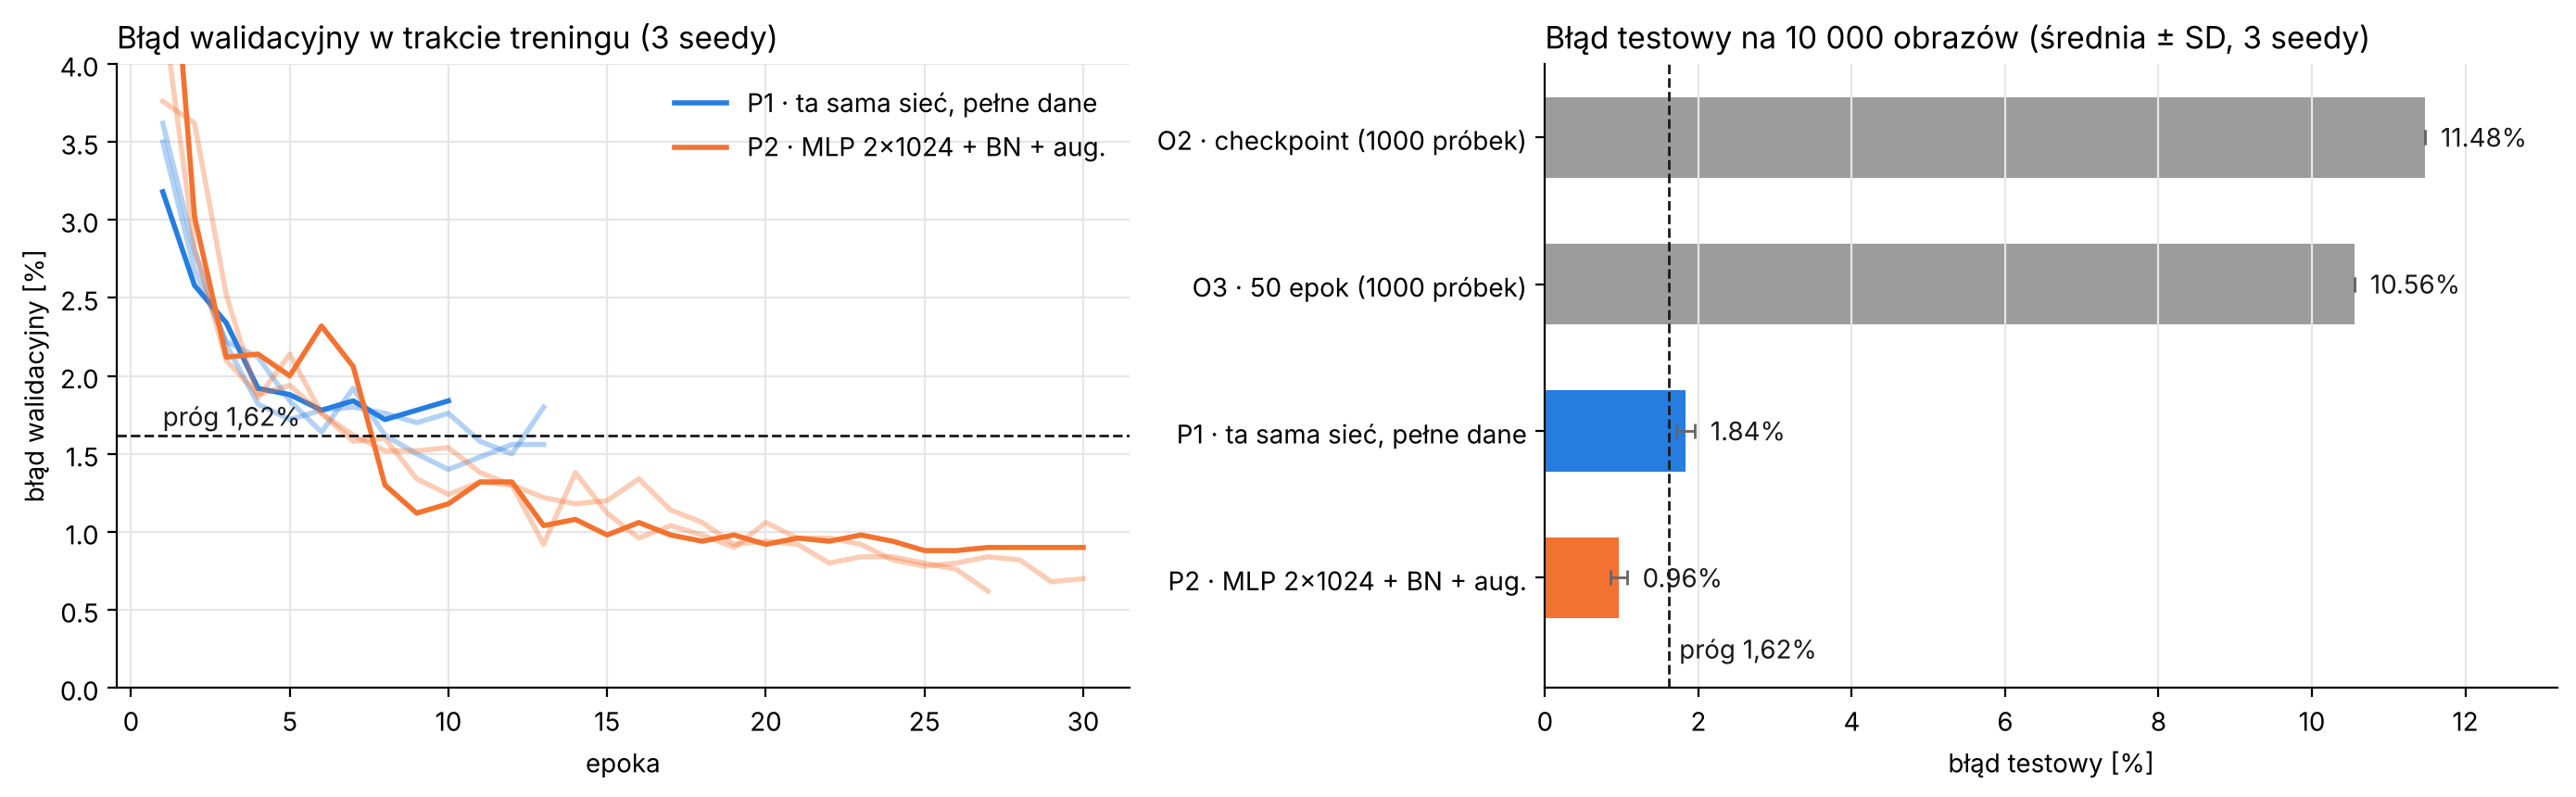

In [9]:
COL = {'P1': '#257de0', 'P2': '#f47230', 'P3': '#00b894', 'old': '#9c9c9c'}
R = {k: v for k, v in {'P1': R_P1, 'P2': R_P2, 'P3': R_P3}.items() if v}
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True,
                     'grid.color': '#e6e6e6', 'grid.linewidth': 0.8, 'font.size': 10})
fig, ax = plt.subplots(1, 2, figsize=(14, 4.4))
for n in R:
    for i, r in enumerate(R[n]):
        e = 100 * (1 - np.array(r['history']['val_acc']))
        ax[0].plot(range(1, len(e) + 1), e, color=COL[n], lw=2, alpha=1 if i == 0 else 0.35,
                   label=NAMES[n] if i == 0 else None)
ax[0].axhline(1.62, color='#191919', lw=1, ls='--'); ax[0].text(1, 1.68, 'próg 1,62%', color='#191919')
ax[0].set_ylim(0, 4); ax[0].set_xlabel('epoka'); ax[0].set_ylabel('błąd walidacyjny [%]')
ax[0].set_title('Błąd walidacyjny w trakcie treningu (3 seedy)', loc='left'); ax[0].legend(frameon=False)

labels = ['O2 · checkpoint (1000 próbek)', 'O3 · 50 epok (1000 próbek)'] + [NAMES[n] for n in R]
vals = [old['O2'][1], old['O3'][1]] + [np.mean([r['test_err'] for r in R[n]]) for n in R]
sds = [0, 0] + [np.std([r['test_err'] for r in R[n]], ddof=1) for n in R]
cols = [COL['old'], COL['old']] + [COL[n] for n in R]
yy = np.arange(len(vals))[::-1]
ax[1].barh(yy, vals, xerr=sds, color=cols, height=0.55, capsize=3, error_kw=dict(lw=1, ecolor='#666666'))
for y_, v, sd_ in zip(yy, vals, sds): ax[1].text(v + sd_ + 0.2, y_, f'{v:.2f}%', va='center', color='#191919')
ax[1].set_yticks(yy, labels); ax[1].grid(axis='y', visible=False)
ax[1].axvline(1.62, color='#191919', lw=1, ls='--'); ax[1].text(1.75, yy[-1] - 0.55, 'próg 1,62%', color='#191919')
ax[1].set_ylim(yy[-1] - 0.75, yy[0] + 0.5)
ax[1].set_xlim(0, max(vals) * 1.15); ax[1].set_xlabel('błąd testowy [%]')
ax[1].set_title('Błąd testowy na 10 000 obrazów (średnia ± SD, 3 seedy)', loc='left')
plt.tight_layout(); plt.show()

## 5. Wybór modelu na walidacji i test hipotez (według protokołu)
- **H1:** wybrany model ma błąd testowy < 1,62% dla **każdego** z 3 seedów.
- **H2:** wybrany model jest istotnie lepszy od P1 (ta sama sieć co w checkpoincie, pełne dane). Test McNemara dla każdego seeda, korekta Holma.

In [10]:
sel = min(R, key=lambda n: np.mean([r['val_err'] for r in R[n]]))
print('Średni błąd walidacyjny:', {n: round(float(np.mean([r['val_err'] for r in R[n]])), 3) for n in R})
print('Wybrany na walidacji:', NAMES[sel])

def mcnemar(a, b):
    a_ok, b_ok = a.argmax(1) == yte, b.argmax(1) == yte
    only_a, only_b = int((a_ok & ~b_ok).sum()), int((~a_ok & b_ok).sum())
    return only_a, only_b, binomtest(only_a, only_a + only_b, 0.5).pvalue

def holm(ps):
    order, m, out, run = np.argsort(ps), len(ps), np.empty(len(ps)), 0
    for k, i in enumerate(order): run = max(run, min(1, (m - k) * ps[i])); out[i] = run
    return out

H1 = all(round(r['test_err'], 4) < 1.62 for r in R[sel])
tests = [mcnemar(np.load(f'{RES}/{sel}_s{s}_test.npy'), np.load(f'{RES}/P1_s{s}_test.npy')) for s in (0, 1, 2)]
padj = holm([t[2] for t in tests])
for s, (a, b_, p), pa in zip((0, 1, 2), tests, padj):
    print(f'seed {s}: tylko {sel} trafia={a}, tylko P1 trafia={b_}, p={p:.2e}, p_Holm={pa:.2e}')
H2 = sel != 'P1' and all(pa < 0.05 and a > b_ for (a, b_, _), pa in zip(tests, padj))
print(f'\nH1 (błąd < 1,62% w każdym seedzie): {H1}\nH2 (istotnie lepszy od P1): {H2}')
print('WERDYKT:', 'SUKCES' if H1 and H2 else 'PORAŻKA', 'według protokołu')

Średni błąd walidacyjny: {'P1': 1.66, 'P2': 0.813}
Wybrany na walidacji: P2 · MLP 2×1024 + BN + aug.
seed 0: tylko P2 trafia=139, tylko P1 trafia=36, p=1.76e-15, p_Holm=5.28e-15
seed 1: tylko P2 trafia=122, tylko P1 trafia=28, p=3.43e-15, p_Holm=6.86e-15
seed 2: tylko P2 trafia=109, tylko P1 trafia=43, p=8.54e-08, p_Holm=8.54e-08

H1 (błąd < 1,62% w każdym seedzie): True
H2 (istotnie lepszy od P1): True
WERDYKT: SUKCES według protokołu


### Gdzie się myli najlepszy model?

P2 seed 1: 86 błędów na 10 000
Najczęstsze pomyłki (prawda→predykcja): [(9, 4, 8), (4, 9, 5), (7, 2, 5), (2, 7, 4), (5, 3, 4)]


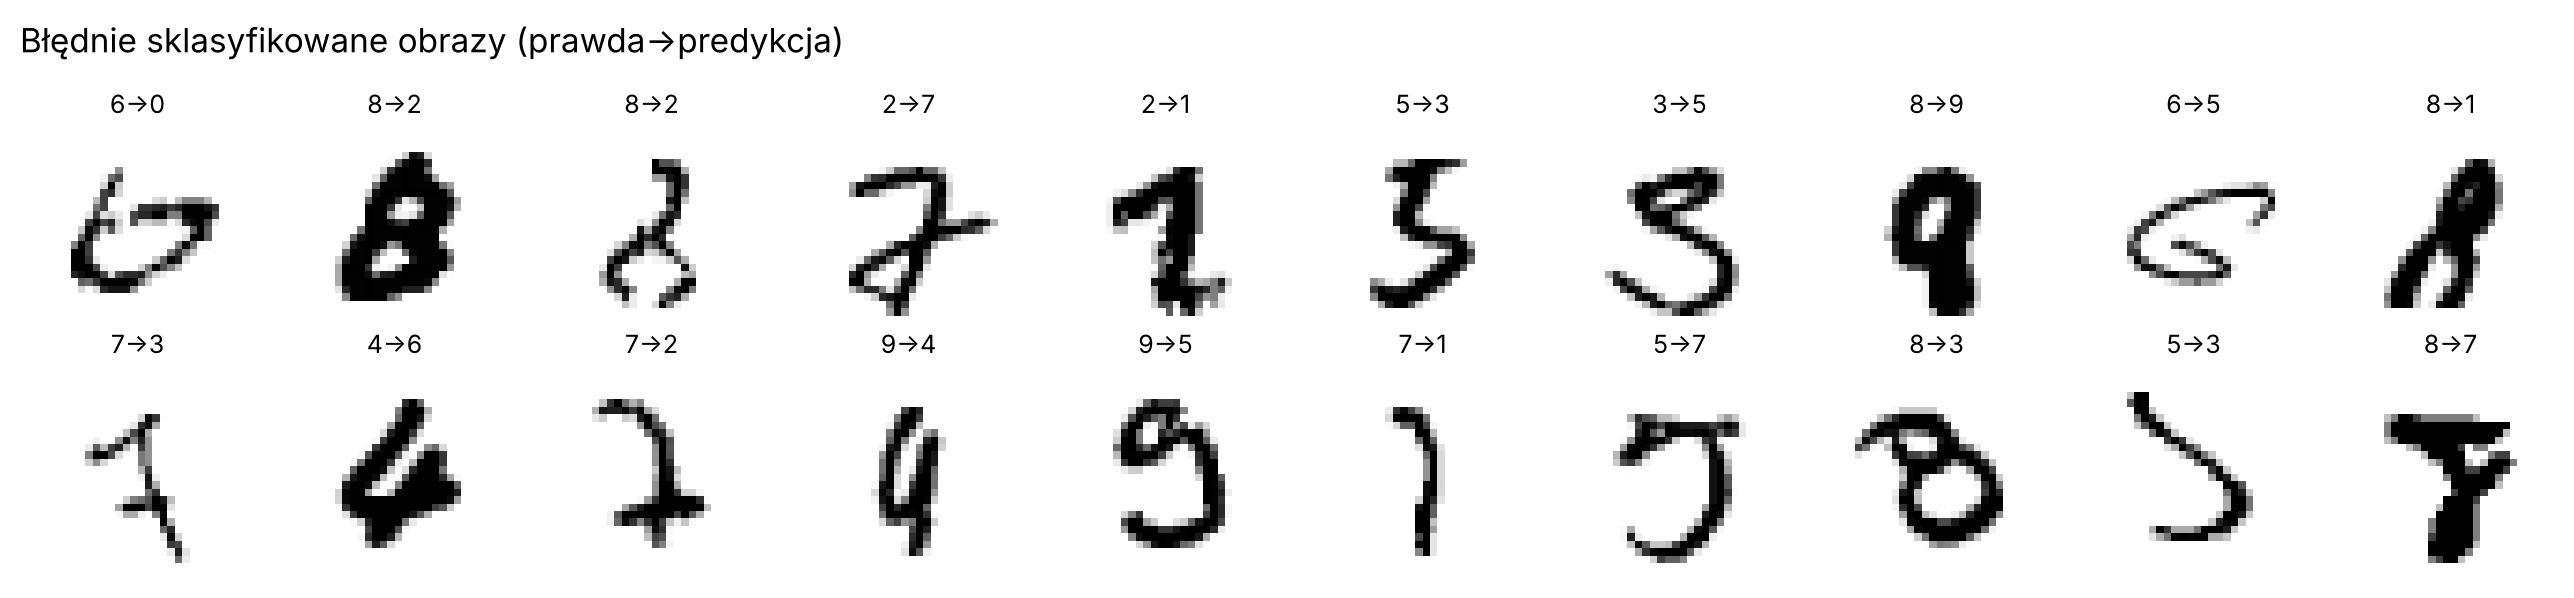

In [11]:
best_seed = min(R[sel], key=lambda r: r['val_err'])['seed']     # najlepszy seed wg walidacji
lt = np.load(f'{RES}/{sel}_s{best_seed}_test.npy'); pred = lt.argmax(1)
wrong = np.where(pred != yte)[0]
print(f'{sel} seed {best_seed}: {len(wrong)} błędów na 10 000')
cm = pd.crosstab(pd.Series(yte, name='prawda'), pd.Series(pred, name='predykcja'))
pairs = [(int(i), int(j), int(cm.loc[i, j])) for i in cm.index for j in cm.columns if i != j and cm.loc[i, j] > 0]
print('Najczęstsze pomyłki (prawda→predykcja):', sorted(pairs, key=lambda t: -t[2])[:5])
fig, axs = plt.subplots(2, 10, figsize=(13, 3))
for a, i in zip(axs.ravel(), wrong[:20]):
    a.imshow(Xte[i], cmap='gray_r'); a.set_title(f'{yte[i]}→{pred[i]}', fontsize=9); a.axis('off')
plt.suptitle('Błędnie sklasyfikowane obrazy (prawda→predykcja)', x=0.01, ha='left'); plt.tight_layout(); plt.show()

## 6. Rekomendacja optymalnego rozwiązania

**Werdykt według protokołu: sukces.** Model wybrany na walidacji (P2) ma błąd testowy poniżej 1,62% w każdym z 3 seedów (0,94% / 0,86% / 1,08%; średnio 0,96%).
Jest też istotnie lepszy od tej samej sieci co w checkpoincie, wytrenowanej na pełnych danych (P1): w każdym seedzie McNemar daje p_Holm ≤ 8,5·10⁻⁸.

**Co rekomenduję:** **P2: MLP 2×1024 + BatchNorm + Dropout 0,3 + augmentacja przesunięć ±10% + ReduceLROnPlateau + EarlyStopping.**

| | P1 (ta sama sieć, pełne dane) | **P2 (rekomendowany)** |
|---|---|---|
| Błąd testowy (śr. z 3 seedów) | 1,84% | **0,96%** |
| Test loss | 0,062 | **0,028** |
| Parametry | 407 tys. | 1,87 mln |
| Czas treningu na 2 rdzeniach CPU | ~35 s | ~4,5 min |

**Dlaczego tak:**
1. **Główne ograniczenie checkpointu to dane, nie architektura.** Ta sama sieć na 55 000 obrazów zamiast 1000 schodzi z 11,5% do 1,84% błędu.
   Sama zmiana danych nie wystarcza jednak do progu: żaden seed P1 nie zszedł poniżej 1,62%.
   Ciekawostka: ensemble trzech kopii P1 ma **dokładnie 162 błędy, czyli równo 1,62%**. Możliwe, że stąd pochodzi próg w zadaniu.
2. **Granicę przekraczają BatchNorm, mocniejszy dropout i augmentacja przesunięć.** Pozwalają trenować dłużej bez przeuczenia (krzywe P2 opadają do 30. epoki).
   P2 poprawia 109–139 obrazów, na których myli się P1, a psuje tylko 28–43.
3. **Pozostałe błędy** to głównie pary 9↔4 i 7↔2, w dużej części cyfry wieloznaczne także dla człowieka.

**Wariant maksymalnej dokładności (opisowo):** uśrednienie 3 modeli P2 daje 0,90% błędu (loss 0,025), ale kosztem 3× większego modelu i czasu.

**Odstępstwo od protokołu:** próba P3 (CNN) nie została uruchomiona, bo na CPU trwałaby ok. 2 godzin. Wybór zapadł więc między P1 i P2.
W Colab z GPU ustaw `RUN_P3 = True`: CNN z augmentacją zwykle osiąga na MNIST ok. 0,4–0,6%, ale **tutaj tego nie sprawdzono**.
Zbiór testowy był już oglądany, więc wynik P3 będzie porównaniem opisowym, nie nowym testem hipotezy.


## 7. Tabela zbiorcza: wszystkie podejścia, stare i nowe

In [12]:
def ens(n):   # opisowo: uśrednienie softmaxów 3 seedów
    P = [tf.nn.softmax(np.load(f'{RES}/{n}_s{s}_test.npy')).numpy() for s in (0, 1, 2)]
    p = np.mean(P, 0)
    return float(-np.log(p[np.arange(len(yte)), yte] + 1e-12).mean()), float(100 * (p.argmax(1) != yte).mean())

rows = [
    ('O1', 'stare', 'Sieć z checkpointu, nietrenowana', '—', old['O1'][2], np.nan, old['O1'][0], old['O1'][1], np.nan),
    ('O2', 'stare', 'Checkpoint cp.ckpt (10 epok, 1000 próbek)', '1 000', old['O2'][2], np.nan, old['O2'][0], old['O2'][1], np.nan),
    ('O3', 'stare', 'Ta sama sieć, 50 epok, 1000 próbek', '1 000', old['O3'][2], np.nan, old['O3'][0], old['O3'][1], np.nan),
]
for n, opis in [('P1', 'Ta sama sieć (Dense 512), pełne dane, early stopping'),
                ('P2', 'MLP 2×1024 + BatchNorm + Dropout + przesunięcia'),
                ('P3', 'CNN 2 bloki conv + BN + Dropout + augmentacje')]:
    rs = R.get(n)
    if not rs:
        rows.append((n, 'nowe (nieuruchomione)', opis + ' — do uruchomienia w Colab', '55 000', np.nan, np.nan, np.nan, np.nan, np.nan)); continue
    rows.append((n, 'nowe', opis, '55 000', rs[0]['params'], np.mean([r['val_err'] for r in rs]),
                 np.mean([r['test_loss'] for r in rs]), np.mean([r['test_err'] for r in rs]),
                 np.std([r['test_err'] for r in rs], ddof=1)))
for n in R:
    l, e = ens(n)
    rows.append((n + '-ens', 'nowe (opisowo)', f'Ensemble 3 seedów {n}', '55 000', 3 * R[n][0]['params'], np.nan, l, e, np.nan))
T = pd.DataFrame(rows, columns=['ID', 'Rodzaj', 'Podejście', 'Dane treningowe', 'Parametry',
                                'Błąd walid. [%]', 'Test loss', 'Błąd test [%]', 'SD błędu (3 seedy)'])
T['< 1,62%?'] = np.where(T['Błąd test [%]'].isna(), '—', np.where(T['Błąd test [%]'].round(4) < 1.62, '✅', '❌'))
T['Wybrany'] = np.where(T['ID'] == sel, '★', '')
T.style.format({'Parametry': '{:,.0f}', 'Błąd walid. [%]': '{:.2f}', 'Test loss': '{:.4f}',
                'Błąd test [%]': '{:.2f}', 'SD błędu (3 seedy)': '{:.2f}'}, na_rep='—').hide(axis='index')

ID,Rodzaj,Podejście,Dane treningowe,Parametry,Błąd walid. [%],Test loss,Błąd test [%],SD błędu (3 seedy),"< 1,62%?",Wybrany
O1,stare,"Sieć z checkpointu, nietrenowana",—,"407,050",—,2.3924,92.79,—,❌,
O2,stare,"Checkpoint cp.ckpt (10 epok, 1000 próbek)",1 000,"407,050",—,0.3746,11.48,—,❌,
O3,stare,"Ta sama sieć, 50 epok, 1000 próbek",1 000,"407,050",—,0.4460,10.56,—,❌,
P1,nowe,"Ta sama sieć (Dense 512), pełne dane, early stopping",55 000,"407,050",1.66,0.0618,1.84,0.12,❌,
P2,nowe,MLP 2×1024 + BatchNorm + Dropout + przesunięcia,55 000,"1,869,834",0.81,0.0284,0.96,0.11,✅,★
P3,nowe (nieuruchomione),CNN 2 bloki conv + BN + Dropout + augmentacje — do uruchomienia w Colab,55 000,—,—,—,—,—,—,
P1-ens,nowe (opisowo),Ensemble 3 seedów P1,55 000,"1,221,150",—,0.0529,1.62,—,❌,
P2-ens,nowe (opisowo),Ensemble 3 seedów P2,55 000,"5,609,502",—,0.0253,0.90,—,✅,
